# 01 · Is the business growing?
Monthly GMV, orders, average order value and freight share over the analysis period
(2017-01 … 2018-08), and which categories drove the growth.
GMV = items price + freight, BRL; valid orders only (see `docs/data_quality.md`).

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from _common import ACCENT, MUTED, con

db = con()
kpis = db.sql("select * from mart_monthly_kpis where is_analysis_period order by month").df()
kpis[["month", "orders", "customers", "gmv", "avg_order_value", "freight_share", "late_rate"]]

,month,orders,customers,gmv,avg_order_value,freight_share,late_rate
0,2017-01-01,787,753,136943.46,174.006938,0.123008,0.029333
1,2017-02-01,1718,1693,283561.69,165.053370,0.136134,0.029643
2,2017-03-01,2617,2577,425617.96,162.635827,0.134573,0.045562
3,2017-04-01,2377,2345,405848.61,170.739844,0.128140,0.065567
4,2017-05-01,3640,3569,582710.83,160.085393,0.136520,0.029901
5,2017-06-01,3205,3142,499652.24,155.897735,0.139568,0.030303
6,2017-07-01,3946,3872,578753.73,146.668457,0.149401,0.027893
7,2017-08-01,4272,4191,661903.52,154.939963,0.141498,0.029096
8,2017-09-01,4227,4154,717102.72,169.648148,0.133435,0.043855
9,2017-10-01,4547,4481,764756.03,168.189142,0.136745,0.041760


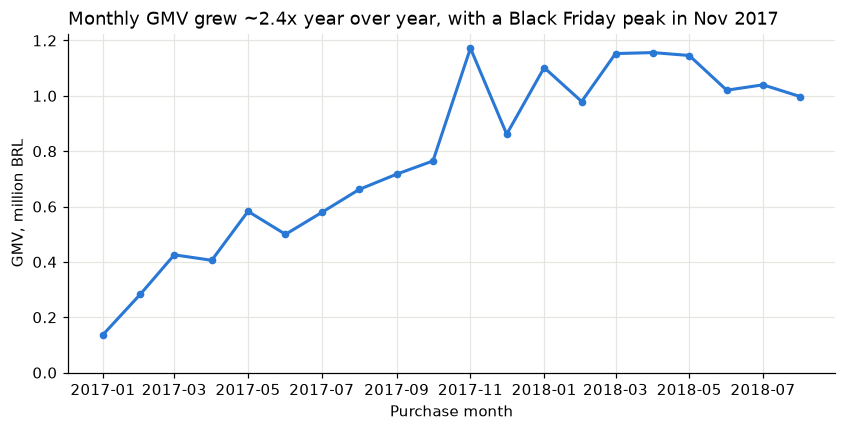

In [2]:
fig, ax = plt.subplots()
ax.plot(kpis.month, kpis.gmv / 1e6, color=ACCENT, linewidth=2, marker="o", markersize=4)
ax.set_title("Monthly GMV grew ~2.4x year over year, with a Black Friday peak in Nov 2017")
ax.set_xlabel("Purchase month")
ax.set_ylabel("GMV, million BRL")
ax.set_ylim(bottom=0)
plt.show()

## Same months, one year apart
January–August 2018 vs January–August 2017, so seasonality does not distort the comparison.

In [3]:
yoy = db.sql("""
    select
        case when month < '2018-01-01' then 'Jan–Aug 2017' else 'Jan–Aug 2018' end as period,
        sum(orders) as orders,
        sum(customers) as customer_months,
        sum(gmv) as gmv,
        sum(gmv) / sum(orders) as avg_order_value,
        sum(freight_value) / sum(gmv) as freight_share
    from mart_monthly_kpis
    where month between '2017-01-01' and '2017-08-01' or month between '2018-01-01' and '2018-08-01'
    group by 1 order by 1
""").df()
yoy["gmv_growth"] = yoy.gmv / yoy.gmv.shift(1) - 1
yoy["orders_growth"] = yoy.orders / yoy.orders.shift(1) - 1
yoy

,period,orders,customer_months,gmv,avg_order_value,freight_share,gmv_growth,orders_growth
0,Jan–Aug 2017,22562.0,22142.0,3574992.04,158.451912,0.138222,NaN,NaN
1,Jan–Aug 2018,53530.0,52929.0,8593137.50,160.529376,0.145709,1.40368,1.372573


## Which categories drove the growth?

In [4]:
cats = db.sql("""
    with p as (
        select
            category,
            sum(price + freight_value) filter (where purchase_month between '2017-01-01' and '2017-08-01') as gmv_2017,
            sum(price + freight_value) filter (where purchase_month between '2018-01-01' and '2018-08-01') as gmv_2018
        from fct_order_items
        where is_valid_order
        group by 1
    )
    select category, coalesce(gmv_2017, 0) as gmv_2017, coalesce(gmv_2018, 0) as gmv_2018,
           coalesce(gmv_2018, 0) - coalesce(gmv_2017, 0) as gmv_change,
           (coalesce(gmv_2018, 0) - coalesce(gmv_2017, 0))
             / sum(coalesce(gmv_2018, 0) - coalesce(gmv_2017, 0)) over () as share_of_growth
    from p order by gmv_change desc
""").df()
cats.head(10)

,category,gmv_2017,gmv_2018,gmv_change,share_of_growth
0,health_beauty,282648.35,882622.55,599974.20,0.119561
1,watches_gifts,220542.18,771337.03,550794.85,0.109761
2,sports_leisure,265204.14,619197.75,353993.61,0.070543
3,bed_bath_table,305780.61,650081.16,344300.55,0.068611
4,computers_accessories,249587.56,591325.29,341737.73,0.068100
5,housewares,161356.80,488822.89,327466.09,0.065256
6,auto,146242.72,403028.70,256785.98,0.051171
7,furniture_decor,224565.68,474747.98,250182.30,0.049856
8,baby,82317.43,298106.63,215789.20,0.043002
9,telephony,77932.50,216842.18,138909.68,0.027681


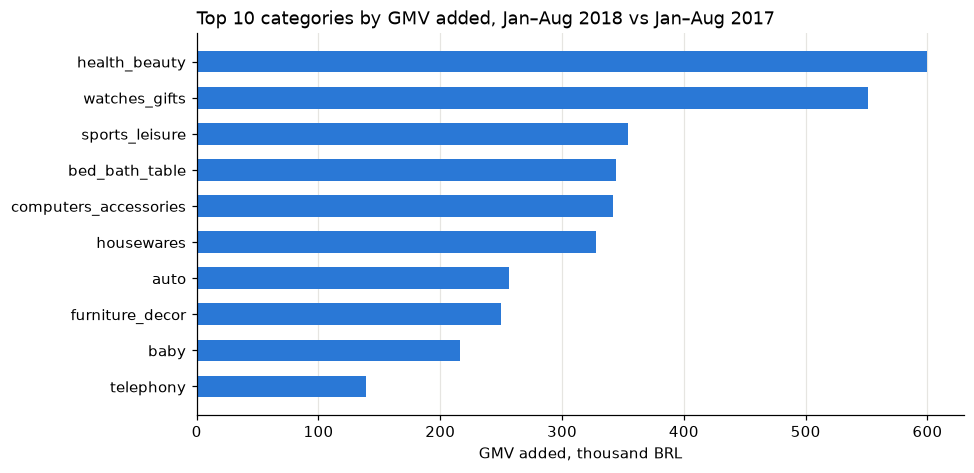

In [5]:
top = cats.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.category, top.gmv_change / 1e3, color=ACCENT, height=0.6)
ax.set_title("Top 10 categories by GMV added, Jan–Aug 2018 vs Jan–Aug 2017")
ax.set_xlabel("GMV added, thousand BRL")
ax.grid(axis="y", visible=False)
plt.show()

In [6]:
print(f"Top 10 categories account for {cats.head(10).share_of_growth.sum():.0%} of GMV growth")

Top 10 categories account for 67% of GMV growth


## Order value and freight

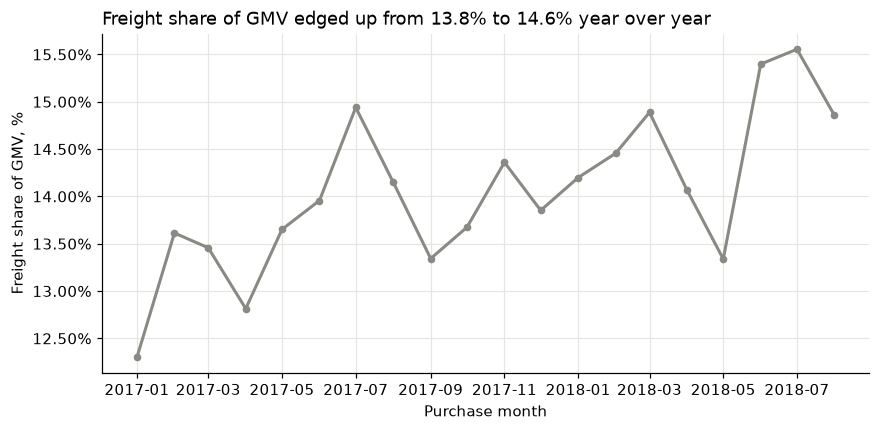

In [7]:
fig, ax = plt.subplots()
ax.plot(kpis.month, kpis.freight_share, color=MUTED, linewidth=2, marker="o", markersize=4)
ax.set_title("Freight share of GMV edged up from 13.8% to 14.6% year over year")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Freight share of GMV, %")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.show()

## Findings
- **GMV grew 2.4x**: 8.59 M BRL in Jan–Aug 2018 vs 3.57 M BRL in Jan–Aug 2017 (+140%);
  orders grew +137% (53,530 vs 22,562).
- **Growth came from more orders, not bigger baskets**: average order value stayed flat
  (158.5 → 160.5 BRL).
- **Growth is broad but led by a few categories**: the top 10 categories added 67% of the new GMV,
  led by health_beauty (+600 k BRL) and watches_gifts (+551 k BRL).
- **Freight share edged up** from 13.8% to 14.6% of GMV.
- **Sales stopped growing in 2018**: monthly GMV stayed between 0.98 and 1.16 M BRL from January to August, below the Nov 2017 peak of 1.17 M.